<a href="https://colab.research.google.com/github/bauhaushm/TP-Delito_en_AMBA/blob/SNP/TP_Delito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Grupal - Laboratorio de Métodos Cuantitativos
**Universidad de Buenos Aires - Facultad de Ciencias Económicas**  
**Tecnicatura Universitaria en Gestión y Análisis de Datos**  
**Segundo Cuatrimestre 2026**

---

### Integrantes del Grupo:
* **Chietino Luna, Micaela** - Registro: 921785 - Usuario GitHub: `@mchietino`
* **Iandoli, Franco** - Registro: 921507 - Usuario GitHub: `@Franco-Iandoli`
* **Ortiz, Naiara** - Registro: 921844 - Usuario GitHub: `@naiaraortizrodriguez`
* **Peralta, Santiago** - Registro: 921431 - Usuario GitHub: `@SantiagoNPeralta`
* **Turrillo, Bruno** - Registro: 921414 - Usuario GitHub: `@bauhaushm`

---

## 1. Introducción y Pregunta de Investigación

Nuestro grupo se focalizará en la temática del delito y su relación con aspectos sociales que pueden influir en él.

**Pregunta de investigación:**
> *¿Cómo se articulan la frecuencia y el tipo de hecho delictivo con la estructura socioeconómica y comercial de CABA y del Conurbano bonaerense?*

Incialmente usamos como fuente principal el Sistema Nacional de Información Criminal (Snic). El URL https://www.argentina.gob.ar/seguridad/estadisticascriminales/bases-de-datos contiene diferentes datasets del cual elegimos "SNIC - Departamentos. Anual. Años 2000-2025".

In [13]:
#importamos las librerías que vamos a utilizar
import pandas as pd #para manipular los archivos
import matplotlib.pyplot as plt #para hacer gráficos
import seaborn as sb #para hacer gráficos
import numpy as np #para realizar operaciones matemáticas

Le pedimos a Pandas que nos haga un filtrado de filas y columnas del dataset. Acotamos el rango a la franja de años 2016-2025 (últimos 10 años) y reducimos la información a las columnass "año", "Provincia", "Departamentos", "Tipo de delito", "Cantidad de Hechos" y "Tasa de delito (cada 100.000 habitantes)". Nombramos al nuevo dataset obtenido.

In [14]:
# 1. Cargar únicamente las columnas A, C, E, G, H, M (índices 0, 2, 4, 6, 7, 12)
columnas = [0, 2, 4, 6, 7, 12]
url = "https://cloud-snic.minseg.gob.ar/Bases/SNIC/snic-departamentos-anual.xlsx"

df = pd.read_excel(url, usecols=columnas)
# 2. Filtrar únicamente para los años entre 2016 y 2025
df_filtrado = df[(df['anio'] >= 2016) & (df['anio'] <= 2025)]

# 3. Verificar el resultado
print(f"El dataset filtrado contiene {len(df_filtrado)} filas y {len(df_filtrado.columns)} columnas.")
print("Años incluidos:", sorted(df_filtrado['anio'].unique()))

# 4. Guardar el nuevo dataset resultante
df_filtrado.to_excel('snic_2016_2025_filtrado.xlsx', index=False)
df_filtrado.to_csv('snic_2016_2025_filtrado.csv', index=False)

El dataset filtrado contiene 306318 filas y 6 columnas.
Años incluidos: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


Visualizamos el nuevo dataframe generado

In [15]:
df_filtrado

,anio,provincia_nombre,departamento_nombre,codigo_delito_snic_nombre,cantidad_hechos,tasa_hechos
7936,2016,Ciudad Autónoma de Buenos Aires,Comuna 1,Homicidios dolosos,30,11.902259
7937,2016,Ciudad Autónoma de Buenos Aires,Comuna 1,Abusos sexuales con acceso carnal (violaciones),0,0.000000
7938,2016,Ciudad Autónoma de Buenos Aires,Comuna 1,Otros delitos contra la integridad sexual,0,0.000000
7939,2016,Ciudad Autónoma de Buenos Aires,Comuna 1,Delitos contra el estado civil,0,0.000000
7940,2016,Ciudad Autónoma de Buenos Aires,Comuna 1,Amenazas,0,0.000000
...,...,...,...,...,...,...
569875,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Lesiones dolosas,341,433.627081
569876,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Lesiones culposas en Accidentes Viales,70,89.014357
569877,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Lesiones culposas por otros hechos,1,1.271634
569878,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Otros delitos contra las personas,879,1117.765994


Contamos el total general de valores nulos (NaN) de todo el dataset:

In [16]:
df_filtrado.isna().sum()

,0
anio,0
provincia_nombre,0
departamento_nombre,122
codigo_delito_snic_nombre,0
cantidad_hechos,0
tasa_hechos,13603


Antes de modificar los datos nulos (Nan), evaluamos la magnitud del problema verificando la cantidad por columna y la proporción en relación al total de datos de esa columna

In [17]:
# Cantidad de nulos por columna
df.isnull().sum()

# Porcentaje de nulos por columna
(df.isnull().sum() / len(df)) * 100

,0
anio,0.000000
provincia_nombre,0.000000
departamento_nombre,0.021408
codigo_delito_snic_nombre,0.000000
cantidad_hechos,0.000000
tasa_hechos,4.481294


"Se detectó un 0,02% de valores nulos en departamento_nombre correspondientes a hechos reportados sin ubicación subprovincial específica, los cuales fueron imputados bajo la etiqueta 'Departamento sin determinar' para conservar la totalidad de los delitos registrados. Asimismo, el 4,48% de nulos en tasa_hechos se mantuvo sin imputar debido a la imposibilidad metodológica de calcular tasas poblacionales en geografías no delimitadas, asegurando no sesgar los cálculos de tendencia con ceros ficticios."

In [18]:
# Imputar los valores nulos en departamento_nombre
df_filtrado['departamento_nombre'] = df_filtrado['departamento_nombre'].fillna('Departamento sin determinar')

/tmp/ipykernel_3036/762855557.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtrado['departamento_nombre'] = df_filtrado['departamento_nombre'].fillna('Departamento sin determinar')


In [19]:
# Verificamos que se aplicó correctamente
(df_filtrado.isnull().sum() / len(df_filtrado)) * 100

,0
anio,0.00000
provincia_nombre,0.00000
departamento_nombre,0.00000
codigo_delito_snic_nombre,0.00000
cantidad_hechos,0.00000
tasa_hechos,4.44081


In [20]:
# Como pretendemos cruzar datos de este dataset con otro lo renombramos

df_delito = df_filtrado

In [21]:
# Para tener un pantallazo general de la evolución del delito en el area estudiada agrupamos por año la cantidad de hechos

# Agrupar por año y sumar la cantidad total de delitos por cada uno
df_delito_por_anio = df_delito.groupby('anio', as_index=False)['cantidad_hechos'].sum()

# Mostrar el nuevo dataset resultante
df_delito_por_anio

,anio,cantidad_hechos
0,2016,1593233
1,2017,1669574
2,2018,1750484
3,2019,1937973
4,2020,1655061
5,2021,1772063
6,2022,1838614
7,2023,2000875
8,2024,2069909
9,2025,1954024


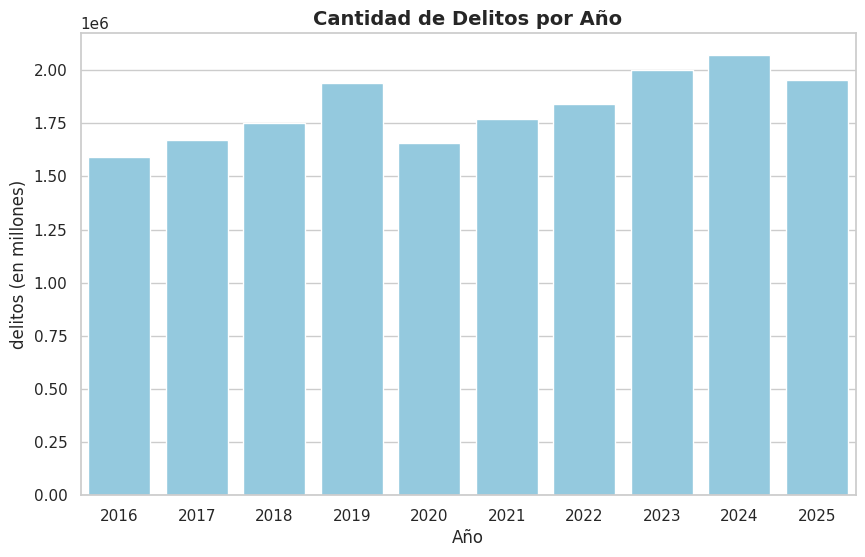

In [22]:
# Graficamos

# Configurar el estilo del gráfico
sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear el gráfico de barras verticales
ax = sb.barplot(
    data=df_delito_por_anio,
    x='anio',
    y='cantidad_hechos',
    color='skyblue'
)

# Configurar títulos y etiquetas de los ejes
plt.title('Cantidad de Delitos por Año', fontsize=14, fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('delitos (en millones)', fontsize=12)  # Eje Y nombrado como "delitos"

# Mostrar el gráfico
plt.show()

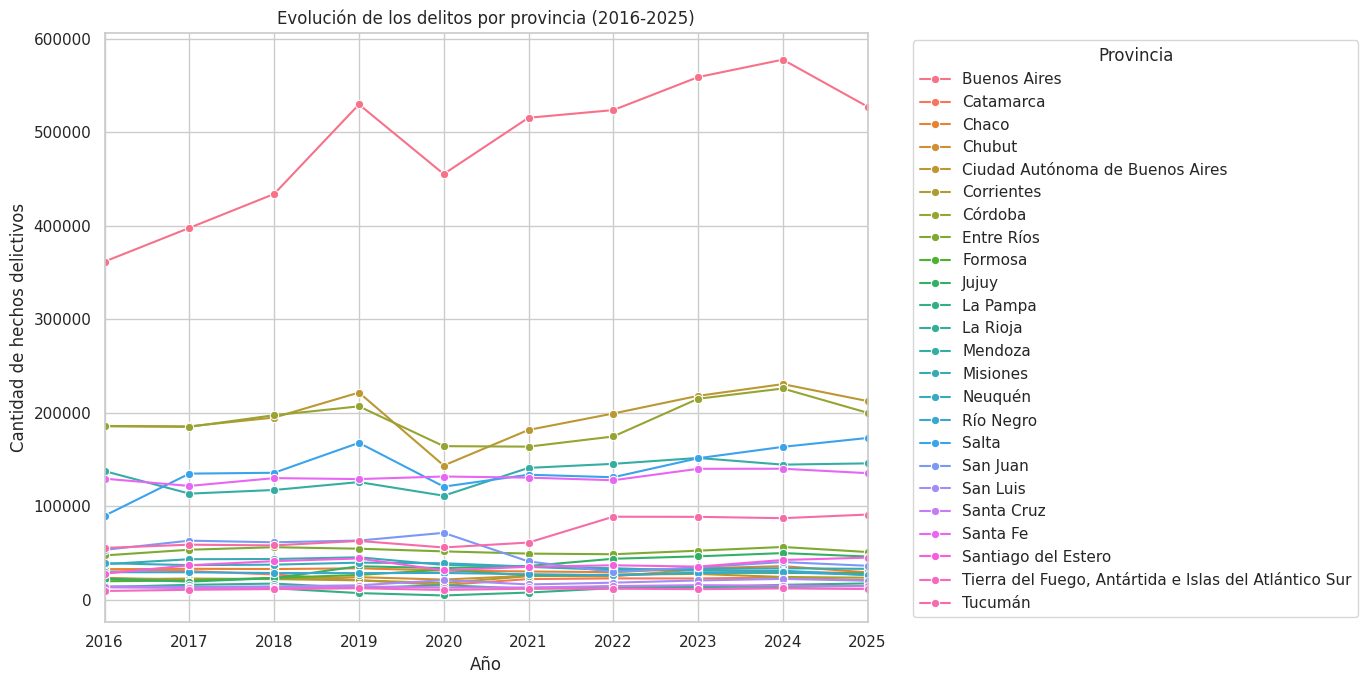

In [23]:
# Filtrar los años 2016 a 2025
df_periodo = df[
    (df["anio"] >= 2016) &
    (df["anio"] <= 2025)
].copy()

# Sumar los delitos por provincia y año
delitos_provincia_anio = (
    df_periodo
    .groupby(["anio", "provincia_nombre"])["cantidad_hechos"]
    .sum()
    .reset_index()
)

# Crear el gráfico
plt.figure(figsize=(14, 7))

sb.lineplot(
    data=delitos_provincia_anio,
    x="anio",
    y="cantidad_hechos",
    hue="provincia_nombre",
    marker="o"
)

plt.title("Evolución de los delitos por provincia (2016-2025)")
plt.xlabel("Año")
plt.ylabel("Cantidad de hechos delictivos")
plt.xticks(range(2016, 2026))
plt.xlim(2016, 2025)
plt.legend(title="Provincia", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

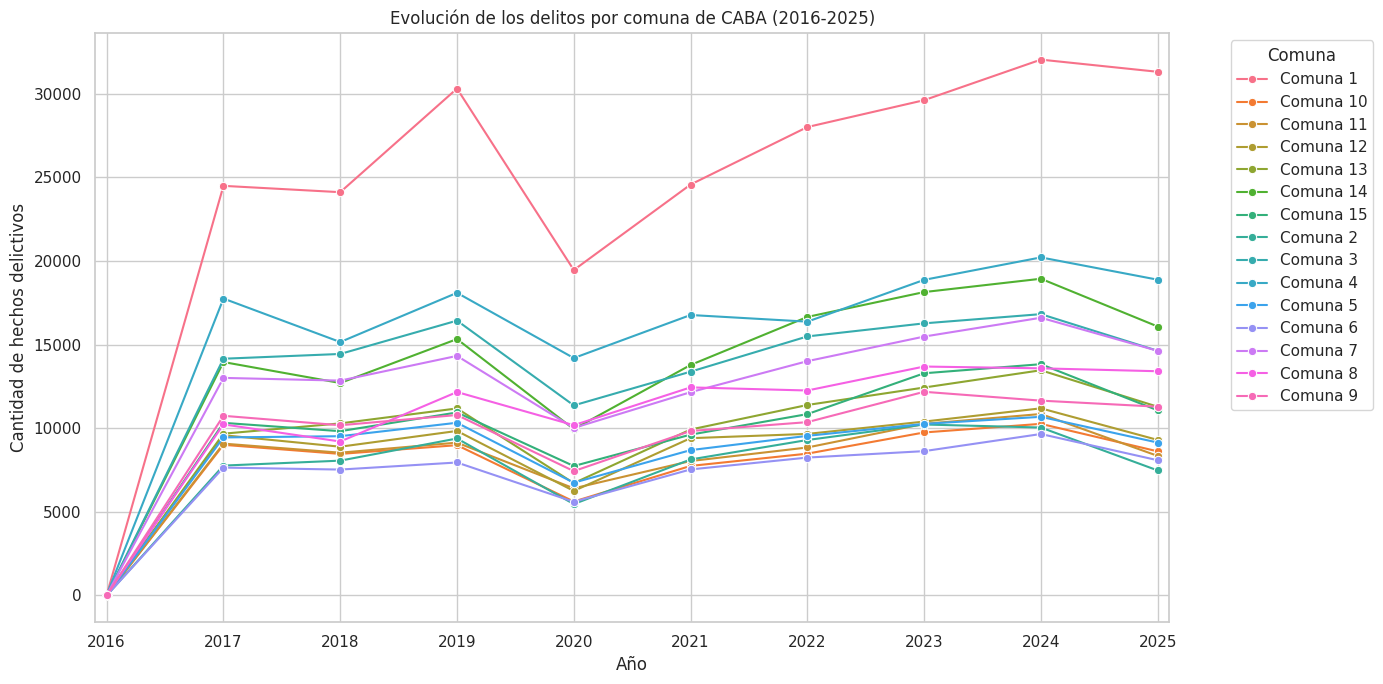

In [64]:
# Filtramos los datos para trabajar únicamente con CABAentre los años 2016 y 2025, excluyendo los departament que no están determinados.
datos_caba = df[
    (df["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires") &
    (df["anio"] >= 2016) &
    (df["anio"] <= 2025) &
    (df["departamento_nombre"] != "Departamento sin determinar")
].copy()

# Agrupamos los datos por año y comuna para obten la cantidad total de hechos delictivos de cada una.
delitos_comuna_anio = (
    datos_caba
    .groupby(["anio", "departamento_nombre"], as_index=False)
    ["cantidad_hechos"]
    .sum()
)

# Definimos el tamaño del gráfico.
plt.figure(figsize=(14, 7))

# Creamos un gráfico de líneas para visualizar la evolució de los hechos delictivos de cada comuna a lo largo del tiempo.
sb.lineplot(
    data=delitos_comuna_anio,
    x="anio",
    y="cantidad_hechos",
    hue="departamento_nombre",
    marker="o"
)

# Ajustamos los límites del eje horizontal para dejarun pequeño margen antes de 2016 y después de 2025.
plt.xlim(2015.9, 2025.1)

# Indicamos que aparezcan todos los años del período.
plt.xticks(range(2016, 2026))

# Agregamos el título y los nombres de los ejes.
plt.title("Evolución de los delitos por comuna de CABA (2016-2025)")
plt.xlabel("Año")
plt.ylabel("Cantidad de hechos delictivos")

# Colocamos la leyenda a la derecha para identifica la línea correspondiente a cada comuna.
plt.legend(title="Comuna", bbox_to_anchor=(1.05, 1), loc="upper left")

# Ajustamos la distribución para que no se recorte los elementos del gráfico.
plt.tight_layout()

# Mostramos el gráfico.
plt.show()

### Distribución de los barrios por comuna de CABA

La Ciudad Autónoma de Buenos Aires está dividida en 15 comunas que agrupan sus 48 barrios. Para facilitar la interpretación del gráfico, se detalla qué barrios corresponden a cada comuna.

- **Comuna 1:** Retiro, San Nicolás, Puerto Madero, San Telmo, Montserrat y Constitución.
- **Comuna 2:** Recoleta.
- **Comuna 3:** Balvanera y San Cristóbal.
- **Comuna 4:** La Boca, Barracas, Parque Patricios y Nueva Pompeya.
- **Comuna 5:** Almagro y Boedo.
- **Comuna 6:** Caballito.
- **Comuna 7:** Flores y Parque Chacabuco.
- **Comuna 8:** Villa Soldati, Villa Riachuelo y Villa Lugano.
- **Comuna 9:** Liniers, Mataderos y Parque Avellaneda.
- **Comuna 10:** Villa Real, Monte Castro, Versalles, Floresta, Vélez Sarsfield y Villa Luro.
- **Comuna 11:** Villa General Mitre, Villa Devoto, Villa del Parque y Villa Santa Rita.
- **Comuna 12:** Coghlan, Saavedra, Villa Urquiza y Villa Pueyrredón.
- **Comuna 13:** Núñez, Belgrano y Colegiales.
- **Comuna 14:** Palermo.
- **Comuna 15:** Chacarita, Villa Crespo, La Paternal, Villa Ortúzar, Agronomía y Parque Chas.

Esta distribución permite identificar las zonas representadas en el gráfico y comparar la evolución de los hechos delictivos entre las distintas comunas durante el período 2016-2025.